# Ultrasound radiomics in breast NAC

A reproducible POC built by an agent from AGENTS.md. Deterministic execution uses archived sources and reviewed mappings; it does not call language models. Source uncertainties remain visible.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd().resolve()
while not (ROOT / 'src' / 'extraction.py').exists():
    if ROOT == ROOT.parent: raise RuntimeError('Run this notebook from the project folder')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.sources import ingest, OUT
from src.report import read_csv
from src.pipeline import performance_rows, incremental_rows, comparability_rows
from IPython.display import display, SVG
import pandas as pd
def show(name): display(pd.DataFrame(read_csv(name)))
print('Project:', ROOT)
print('Source identity and hashes:', len(ingest()), 'verified full texts')

Project: /home/gabriele/cancer-research/meta-analysis-demo/breast_nac_ultrasound_radiomics_v1
Source identity and hashes: 4 verified full texts


## 1. Research question

Does ultrasound-based radiomics provide incremental value beyond clinical and conventional ultrasound models?

## 2. Why this problem matters

Absolute discrimination and added predictive information answer different questions. High AUC alone does not prove incremental value.

## 3. Selected studies

Four studies were prespecified; this is not an exhaustive search or screening review.

In [2]:
show('evidence_matrix.csv')

,study_id,authors,year,country,centers,design,recruitment_period,N_total,train_N,validation_N,external_validation_N,inclusion_criteria,exclusion_criteria,population,subtype,stage,age,regimen,endpoint,endpoint_definition,pCR_definition,responder_N,nonresponder_N,prevalence,reference_standard,reference_timing,surgery,ultrasound,SWE,CEUS,QUS,scanner,timepoints,image_count,segmentation,segmentation_dimension,operator_count,operator_expertise,interobserver_assessment,segmentation_software,radiomics_software,initial_features,feature_families,preprocessing,normalization,discretization,feature_robustness,feature_selection,final_features,model_types,comparator,algorithm,tuning,cv_strategy,validation_type,source_access
0,YANG_2022,Yang et al.,2022,China,Single center; Guizhou Medical University,Retrospective,December 2018–December 2020 (Methods; abstract...,217,152,65,0,Previously untreated biopsy-confirmed invasive...,Bilateral/multiple lesions; large or poor-qual...,Newly diagnosed invasive breast carcinoma trea...,Molecular typing recorded; Table 1 includes lu...,NR,"Table 1 original columns: [""Variable"", ""Respon...",Paclitaxel and anthracycline-based; 4–8 cycles,RECIST responder / non-responder,At least 30% reduction in longest dimension on...,Not the target endpoint,127,90,0.585253,Radiological size response assessed by two rad...,Pre- versus post-treatment; exact response ass...,NR,B-mode grayscale and conventional Doppler desc...,Not reported,Not reported,Not reported,"GE Logiq E9; linear probe, central frequency 7...",Pretreatment and after 2 NAC cycles,Largest long-axis image per timepoint,Manual 2D ITK-SNAP ROI; reader >5 years; repea...,2D,1,>5 years,NR,ITK-SNAP,USKit 1.3.0,788,"First-order, shape, texture, transform/wavelet",NR,NR,NR,Repeat segmentation ICC >0.7,"ICC >0.7, mRMR, LASSO",RS1:9; RS2:11; delta:8,Radiomics-only; clinical-only; clinical+radiomics,Clinical-only; baseline/early/delta signatures...,Logistic regression,Not reported,10-fold CV in training,Random stratified internal 7:3 holdout,Archived primary full text; identity and SHA-2...
1,WANG_2025,Wang et al.,2025,China,Single center; West China Hospital,Retrospective,April 2020–December 2022,239,167,72,0,Pathological diagnosis; 6–8 anthracycline/taxa...,Prior breast cancer/treatment; pregnancy/lacta...,Female non-metastatic breast cancer patients c...,"Luminal A, Luminal B, HER2-positive, triple-ne...",NR,"Table 1 original columns: [""Factor"", ""NMHR ( n...","Anthracycline and taxane-based, 6–8 cycles",Miller–Payne MHR / non-MHR,Miller–Payne G4–G5 = major histological respon...,MHR includes grades 4 and 5; not equivalent to...,NR,NR,51.5% MHR (reported; overall counts not explicit),Core biopsy versus post-treatment surgical pat...,After completion of NAT and surgery,Yes; definitive surgery after NAT,"B-mode, Doppler, SWE, CEUS; radiomics on grays...",Yes,Yes,Not reported,Siemens OXANA2 ABVS; follow-up same system or ...,Baseline and after 2 NAT cycles,NR,U-Net segmentation with radiologist manual cor...,NR,NR,At least 5 years,NR,U-Net,PyRadiomics 3.1.0,1395,"First-order, morphology, texture, wavelet",Not reported,Not reported,Not reported,NR,Univariate screening; VIF; LASSO; stepwise reg...,Baseline:7; after two cycles:13; delta:10,Clinical+ultrasound; radiomics-only; combined ...,Clinical+conventional multimodal ultrasound; r...,Multivariate logistic regression,NR,LASSO 10-fold CV,Random stratified internal 7:3 holdout,Archived primary full text; identity and SHA-2...
2,WU_2025,Wu et al.,2025,China,Two institutions: Xiangyang First People’s Hos...,Retrospective,Jan 2022–Feb 2024; Mar 2022–Feb 2024,643,NR,NR,271,Invasive breast cancer; complete NAC/surgery; ...,Bilateral cancer; incomplete/non-standard trea...,"Confirmed invasive breast cancer, completed NA...","HR+/HER2−, HER2+, TNBC; distributions in Table...",NR,"Table 1 original columns: [""Characteristics"", ...",NAC; specific regimens not reported,pCR / non-pCR,Postoperative pCR; ypT0/is ypN0 stated i

## 4. Agent-built workflow

Ingestion → source-bound extraction → independent numerical checks → methodology → comparability → synthesis freeze → benchmark → reporting. No hosted agents run at execution.

In [3]:
display(json.loads((OUT / 'pipeline_stages.json').read_text()))

['ingestion',
 'factual extraction',
 'validation',
 'methodological interpretation',
 'comparability',
 'synthesis freeze',
 'benchmark',
 'reporting']

## 5. Structured extraction

Narrative facts have source anchors; performance tables are parsed from archived HTML. SOURCE_BOUND marks a reviewed mapping, not automated clinical adjudication.

In [4]:
show('coverage_summary.csv')

,study_id,fields_expected,fields_present,fields_missing,source_bound_fields,performance_rows,known_auc
0,YANG_2022,54,44,10,53,8,8
1,WANG_2025,54,41,13,47,9,6
2,WU_2025,54,41,13,46,8,8
3,FRONTIERS_2024,54,49,5,50,24,24


## 6. Endpoint harmonization

RECIST, Miller–Payne MHR and pCR stay distinct. Binary normalization does not imply clinical equivalence.

In [5]:
show('endpoint_mapping.csv')

,study,endpoint_name,endpoint_definition,binary_mapping,comparable_to_pCR,notes
0,YANG_2022,RECIST responder / non-responder,At least 30% reduction in longest dimension on...,Target response=1; absence=0 (analysis normali...,no,Original endpoint retained; binary mapping doe...
1,WANG_2025,Miller–Payne MHR / non-MHR,Miller–Payne G4–G5 = major histological respon...,Target response=1; absence=0 (analysis normali...,no,Original endpoint retained; binary mapping doe...
2,WU_2025,pCR / non-pCR,Postoperative pCR; ypT0/is ypN0 stated in Intr...,Target response=1; absence=0 (analysis normali...,category yes; operational definition needs review,Original endpoint retained; binary mapping doe...
3,FRONTIERS_2024,pCR / non-pCR,"No residual invasive carcinoma, DCIS may remai...",Target response=1; absence=0 (analysis normali...,yes,Original endpoint retained; binary mapping doe...


## 7. Timepoint harmonization

Baseline, after two cycles, midpoint, delta and longitudinal models retain their own roles.

In [6]:
show('timepoint_mapping.csv')

,study,timepoints_reported,model_roles
0,YANG_2022,Pretreatment and after 2 NAC cycles,baseline; early-treatment; delta; longitudinal...
1,WANG_2025,Baseline and after 2 NAT cycles,baseline; early-treatment; delta; longitudinal...
2,WU_2025,Pretreatment and midpoint of NAC,longitudinal combined
3,FRONTIERS_2024,Pretreatment before NAC,baseline


## 8. Evidence matrix

Missing values remain NR. Review the original source evidence for consequential fields.

In [7]:
show('evidence_provenance.csv')

,study_id,variable,value,source_section,source_table,source_excerpt,source_identifier
0,YANG_2022,authors,Yang et al.,Methods / Patients,NR,Ethical approval for this retrospective study ...,https://www.frontiersin.org/journals/oncology/...
1,YANG_2022,country,China,Methods / Patients,NR,Ethical approval for this retrospective study ...,https://www.frontiersin.org/journals/oncology/...
2,YANG_2022,centers,Single center; Guizhou Medical University,Methods / Patients,NR,Ethical approval for this retrospective study ...,https://www.frontiersin.org/journals/oncology/...
3,YANG_2022,design,Retrospective,Methods / Patients,NR,Ethical approval for this retrospective study ...,https://www.frontiersin.org/journals/oncology/...
4,YANG_2022,recruitment_period,December 2018–December 2020 (Methods; abstract...,Methods / Patients,NR,Ethical approval for this retrospective study ...,https://www.frontiersin.org/journals/oncology/...
...,...,...,...,...,...,...,...
510,FRONTIERS_2024,PPV:MLP radiomics:internal_validation,0.571,Results,Table 3,0.694,https://www.frontiersin.org/journals/oncology/...
511,FRONTIERS_2024,NPV:MLP radiomics:internal_validation,0.789,Results,Table 3,0.694,https://www.frontiersin.org/journals/oncology/...
512,FRONTIERS_2024,calibration:MLP radiomics:internal_validation,Calibration curves,Methods / Model evaluation,NR,The predictive performance of 10 ML models was...,https://www.frontiersin.org/journals/oncology/...
513,FRONTIERS_2024,decision_curve:MLP radiomics:internal_validation,DCA training and validation,Methods / Model evaluation,NR,The predictive performance of 10 ML models was...,https://www.frontiersin.org/journals/oncology/...


## 9. Performance comparison

Each estimate has study, model, outcome, dataset and imaging role.

In [8]:
show('performance_wide.csv')

,model_id,model_type,dataset_role,timepoint_role,file,table,row,column,layout,study_id,endpoint,AUC,CI_low,CI_high,extraction_status,source_section,source_table,source_identifier,raw_auc,sensitivity,specificity,accuracy,precision,recall,F1,PPV,NPV,calibration,Brier,decision_curve,threshold,metric_provenance,evidence,dataset_note,reason,reported_figure_CI,CI_source,is_candidate
0,RS1,radiomics-only,training,baseline,YANG_2022.html,3,2,1,auc_row,YANG_2022,RECIST,0.722,0.643,0.802,VERIFIED_TRANSCRIPTION,Results,Table 3,https://www.frontiersin.org/journals/oncology/...,0.722 (0.643–0.802),0.73,0.64,0.678,NR,NR,NR,NR,NR,NR,NR,NR,NR,{},,,,,,
1,RS1,radiomics-only,internal_validation,baseline,YANG_2022.html,3,2,5,auc_row,YANG_2022,RECIST,0.725,0.543,0.814,VERIFIED_TRANSCRIPTION,Results,Table 3,https://www.frontiersin.org/journals/oncology/...,0.725 (0.543–0.814),0.778,0.658,0.677,NR,NR,NR,NR,NR,NR,NR,NR,NR,{},,,,,,
2,RS2,radiomics-only,training,early-treatment,YANG_2022.html,3,3,1,auc_row,YANG_2022,RECIST,0.811,0.742,0.88,VERIFIED_TRANSCRIPTION,Results,Table 3,https://www.frontiersin.org/journals/oncology/...,0.811 (0.742–0.880),0.719,0.841,0.75,NR,NR,NR,NR,NR,NR,NR,NR,NR,{},,,,,,
3,RS2,radiomics-only,internal_validation,early-treatment,YANG_2022.html,3,3,5,auc_row,YANG_2022,RECIST,0.793,0.679,0.908,VERIFIED_TRANSCRIPTION,Results,Table 3,https://www.frontiersin.org/journals/oncology/...,0.793 (0.679–0.908),0.605,0.926,0.723,NR,NR,NR,NR,NR,NR,NR,NR,NR,{},,,,,,
4,Delta RS,radiomics-only,training,delta,YANG_2022.html,3,4,1,auc_row,YANG_2022,RECIST,0.743,0.666,0.82,VERIFIED_TRANSCRIPTION,Results,Table 3,https://www.frontiersin.org/journals/oncology/...,0.743 (0.666–0.820),0.494,0.889,0.678,NR,NR,NR,NR,NR,NR,NR,NR,NR,{},,,,,,
5,Delta RS,radiomics-only,internal_validation,delta,YANG_2022.html,3,4,5,auc_row,YANG_2022,RECIST,0.714,0.582,0.847,VERIFIED_TRANSCRIPTION,Results,Table 3,https://www.frontiersin.org/journals/oncology/...,0.714 (0.582–0.847),0.658,0.741,0.692,NR,NR,NR,NR,NR,NR,NR,NR,NR,{},,,,,,
6,Nomogram RS1+RS2+Ki-67,clinical+radiomics,training,longitudinal combined,YANG_2022.html,3,5,1,auc_row,YANG_2022,RECIST,0.849,0.789,0.908,VERIFIED_TRANSCRIPTION,Results,Table 3,https://www.frontiersin.org/journals/oncology/...,0.849 (0.789–0.908),0.825,0.764,0.75,NR,NR,NR,NR,NR,Hosmer–Lemeshow p=0.11; calibration curves,NR,NR,NR,"{'calibration': {'file': 'YANG_2022.html', 'pa...",,,,,,
7,Nomogram RS1+RS2+Ki-67,clinical+radiomics,internal_validation,longitudinal combined,YANG_2022.html,3,5,5,auc_row,YANG_2022,RECIST,0.866,0.779,0.954,VERIFIED_TRANSCRIPTION,Results,Table 3,https://www.frontiersin.org/journals/oncology/...,0.866 (0.779–0.954),0.852,0.789,0.785,NR,NR,NR,NR,NR,Hosmer–Lemeshow p=0.75; calibration curves,NR,NR,NR,"{'calibration': {'file': 'YANG_2022.html', 'pa...",,,,,,
8,RSA baseline,radiomics-only,training,baseline,,,,,,WANG_2025,MHR,0.69,NR,NR,VERIFIED_TRANSCRIPTION,Results / Model construction,Results prose; Table 3 for main model pairs,https://link.springer.com/article/10.1186/s128...,,NR,NR,NR,NR,NR,NR,NR,NR,NR,NR,NR,NR,{},"{'file': 'WANG_2025.html', 'paragraph': 41, 's...",Training allocation supported by abstract and ...,,,,
9,RSA early,radiomics-only,training,early-treatment,,,,,,WANG_2025,MHR,0.833,NR,NR,VERIFIED_TRANSCRIPTION,Results / Model construction,Results prose; Table 3 for main model pairs,https://link.springer.com/article/10.1186/s128...,,NR,NR,NR,NR,NR,NR,NR,NR,NR,NR,NR,NR,{},"{'file': 'WANG_2025.html', 'paragraph': 41, 's...",Training allocation supported by abstract and ...,,,,


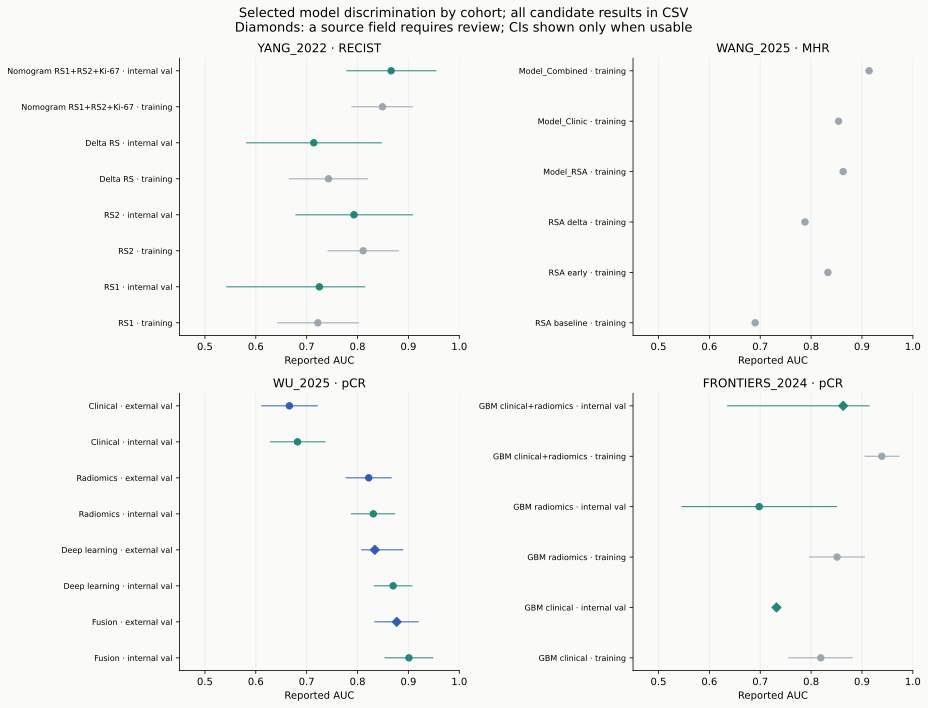

In [9]:
display(SVG(filename=str(ROOT / 'figures' / 'auc_by_model.svg')))

## 10. Incremental value

Equivalent validation contrasts precede training. Statistical tests belong to a specific contrast and dataset. Fusion gains do not isolate radiomics.

In [10]:
show('incremental_value.csv')

,study_id,comparison,model_a,model_b,dataset_role,timepoint_role,auc_a,auc_b,delta_AUC,statistical_test,p_value,classification,reason,source,primary,test_verified,delta_sensitivity,delta_specificity,calibration_difference,net_benefit_difference
0,YANG_2022,D early vs baseline radiomics,RS2,RS1,internal_validation,early-treatment vs baseline,0.793,0.725,0.068,NR,NR,Suggestive,Same internal_validation cohort and RECIST out...,https://www.frontiersin.org/journals/oncology/...,True,False,-0.173,0.268,NR,NR
1,YANG_2022,D early vs baseline radiomics,RS2,RS1,training,early-treatment vs baseline,0.811,0.722,0.089,NR,NR,Indeterminate,Same training cohort and RECIST outcome. Secon...,https://www.frontiersin.org/journals/oncology/...,False,False,-0.011,0.201,NR,NR
2,YANG_2022,E delta vs baseline radiomics,Delta RS,RS1,internal_validation,delta vs baseline,0.714,0.725,-0.011,NR,NR,Not demonstrated,Same internal_validation cohort and RECIST out...,https://www.frontiersin.org/journals/oncology/...,True,False,-0.12,0.083,NR,NR
3,YANG_2022,E delta vs baseline radiomics,Delta RS,RS1,training,delta vs baseline,0.743,0.722,0.021,DeLong,0.086,Not demonstrated,Same training cohort and RECIST outcome. Secon...,https://www.frontiersin.org/journals/oncology/...,False,True,-0.236,0.249,NR,NR
4,YANG_2022,G nomogram vs baseline radiomics,Nomogram RS1+RS2+Ki-67,RS1,internal_validation,longitudinal combined vs baseline,0.866,0.725,0.141,NR,NR,Suggestive,Same internal_validation cohort and RECIST out...,https://www.frontiersin.org/journals/oncology/...,True,False,0.074,0.131,NR,NR
5,YANG_2022,G nomogram vs baseline radiomics,Nomogram RS1+RS2+Ki-67,RS1,training,longitudinal combined vs baseline,0.849,0.722,0.127,NR,NR,Indeterminate,Same training cohort and RECIST outcome. Secon...,https://www.frontiersin.org/journals/oncology/...,False,False,0.095,0.124,NR,NR
6,YANG_2022,G nomogram vs early radiomics,Nomogram RS1+RS2+Ki-67,RS2,internal_validation,longitudinal combined vs early-treatment,0.866,0.793,0.073,NR,NR,Suggestive,Same internal_validation cohort and RECIST out...,https://www.frontiersin.org/journals/oncology/...,True,False,0.247,-0.137,NR,NR
7,YANG_2022,G nomogram vs early radiomics,Nomogram RS1+RS2+Ki-67,RS2,training,longitudinal combined vs early-treatment,0.849,0.811,0.038,NR,NR,Indeterminate,Same training cohort and RECIST outcome. Secon...,https://www.frontiersin.org/journals/oncology/...,False,False,0.106,-0.077,NR,NR
8,YANG_2022,A radiomics vs clinical-only,NR,NR,unavailable,NR,NR,NR,NR,NR,NR,Indeterminate,"No isolated, source-supported comparator contr...",https://www.frontiersin.org/journals/oncology/...,True,False,NR,NR,NR,NR
9,YANG_2022,B radiomics vs conventional ultrasound-only,NR,NR,unavailable,NR,NR,NR,NR,NR,NR,Indeterminate,"No isolated, source-supported comparator contr...",https://www.frontiersin.org/journals/oncology/...,True,False,NR,NR,NR,NR


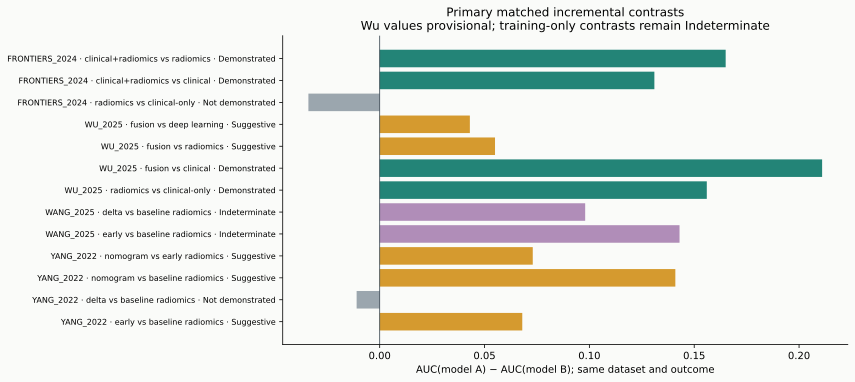

In [11]:
display(SVG(filename=str(ROOT / 'figures' / 'incremental_value.svg')))

## 11. Comparability

Nine criteria; unavailable excluded; high ≥.75, moderate ≥.50, low <.50. A score does not establish poolability.

In [12]:
show('comparability_matrix.csv')

,study_a,study_b,alignment_score,evaluated_criteria,rating,reason
0,YANG_2022,WANG_2025,0.611111,9,moderate,5.5/9 evaluable criteria; unavailable excluded...
1,YANG_2022,WU_2025,0.5,8,moderate,4/8 evaluable criteria; unavailable excluded. ...
2,YANG_2022,FRONTIERS_2024,0.666667,9,moderate,6/9 evaluable criteria; unavailable excluded. ...
3,WANG_2025,WU_2025,0.4375,8,low,3.5/8 evaluable criteria; unavailable excluded...
4,WANG_2025,FRONTIERS_2024,0.555556,9,moderate,5/9 evaluable criteria; unavailable excluded. ...
5,WU_2025,FRONTIERS_2024,0.625,8,moderate,5/8 evaluable criteria; unavailable excluded. ...


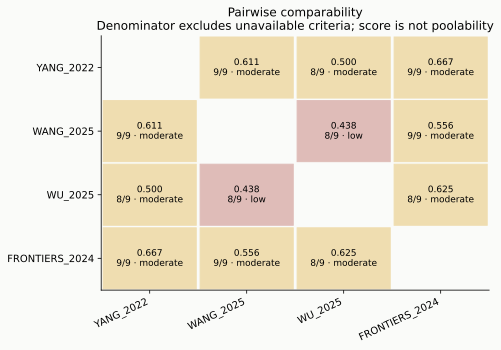

In [13]:
display(SVG(filename=str(ROOT / 'figures' / 'pairwise_comparability.svg')))

## 12. Poolability

Joint endpoint/timepoint/model/validation strata must contain independent studies with usable precision. No automatic meta-analysis.

In [14]:
show('poolability_candidates.csv')

,endpoint,timepoint,model_type,dataset_role,studies,study_count,precision_available,eligible,reason
0,RECIST,baseline,radiomics-only,internal_validation,YANG_2022,1,True,False,Fewer than two independent studies in this joi...
1,RECIST,delta,radiomics-only,internal_validation,YANG_2022,1,True,False,Fewer than two independent studies in this joi...
2,RECIST,early-treatment,radiomics-only,internal_validation,YANG_2022,1,True,False,Fewer than two independent studies in this joi...
3,RECIST,longitudinal combined,clinical+radiomics,internal_validation,YANG_2022,1,True,False,Fewer than two independent studies in this joi...
4,pCR,baseline,clinical+radiomics,internal_validation,FRONTIERS_2024,1,False,False,Fewer than two independent studies in this joi...
5,pCR,baseline,radiomics-only,internal_validation,FRONTIERS_2024,1,False,False,Fewer than two independent studies in this joi...
6,pCR,longitudinal combined,clinical+radiomics+deep learning,external_validation,WU_2025,1,False,False,Fewer than two independent studies in this joi...
7,pCR,longitudinal combined,clinical+radiomics+deep learning,internal_validation,WU_2025,1,True,False,Fewer than two independent studies in this joi...
8,pCR,longitudinal combined,radiomics-only,external_validation,WU_2025,1,True,False,Fewer than two independent studies in this joi...
9,pCR,longitudinal combined,radiomics-only,internal_validation,WU_2025,1,True,False,Fewer than two independent studies in this joi...


## 13. Final synthesis

Content-addressed freezes are retained. The current synthesis is read from the same artifact as the report.

In [15]:
display(json.loads((OUT / 'synthesis_frozen.json').read_text()))

{'benchmark_consulted_in_this_primary_run': False,
 'benchmark_exposure_note': 'The inherited project already consulted the benchmark; this rerun is not blind or independent of prior exposure.',
 'code_sha256': {'src/__init__.py': 'e56f75261d014295e7e06840f18c8a6f5219fcff4a08c3322c893be15ccffe4c',
  'src/analysis.py': '5a248eed3501597256827992ef1f8d00945a29004a259b10fc4e5dabb8c5315b',
  'src/audit.py': 'b9f8b4dd8f7984c4b9d0169d9b7e1c525017953c2e5b343964b3017cdd03aae7',
  'src/data.py': '3e232c1dc9e1dd5af4e9333aab2abcfc651e566124ddf1eae402237686d80305',
  'src/extraction.py': 'cfe4565846063644f70621baccbe961aa91b2b4b53ac8fbc39eccca1bc34c270',
  'src/pipeline.py': 'a8f830e5ac0f6c824d372b91b1b4886887675274b52c6260c9a90ce0b4eea750',
  'src/plots.py': '485fa53e344ed925590b739354619adc0869f62fd08c163dc686a2b87716bf15',
  'src/report.py': '97235d4e26fd19c871013def7dcb9e3f5e1b152e36d2eda3ebe6469c1fbf5c7f',
  'src/sources.py': '5a4f3f78c1e48d0f8fb5599af391446eb96e3c19e75c8389d1d1184a7a377e1d',


## 14. Benchmark check

This step follows the current primary freeze. Prior benchmark exposure is declared; this is not a blind replication.

In [16]:
print((OUT / 'benchmark_comparison.md').read_text() if (OUT / 'benchmark_comparison.md').exists() else 'Benchmark not yet accessed in this run')

# External methodological benchmark

Ultrasound-based radiomics for early predicting response to neoadjuvant chemotherapy in patients with breast cancer: a systematic review with meta-analysis (2024), DOI 10.1007/s11547-024-01783-1.

Source: https://link.springer.com/article/10.1007/s11547-024-01783-1
Access: Publisher abstract and subscription preview only; full review not accessible

The review searched four databases through 1 January 2023 and included eight studies. It assessed methods using RQS and QUADAS-2; mean RQS was 12.88 (35.8% of the maximum). Pooled sensitivity was 0.87 (95% CI 0.81–0.92), specificity 0.78 (0.72–0.83). It described potential predictive usefulness while calling for rigorous multicenter prospective confirmation because the evidence was limited and methodologically weak. These are abstract-level findings, not a full-text methodological audit.

The review predates the two 2025 studies and covers a broader evidence set. Its pooled accuracy is not a pooled incre

## 15. Limitations

Curated semantic interpretations, missing validation metrics and source contradictions limit conclusions. See the open checks and their impact.

In [17]:
show('validation_checks.csv')

,study_id,field,extractor_value,validator_value,status,reason,source,issue_type
0,YANG_2022,N_total,217,217,MATCH,Independent numerical source witness; external...,https://www.frontiersin.org/journals/oncology/...,none
1,YANG_2022,train_N,152,152,MATCH,Independent numerical source witness; external...,https://www.frontiersin.org/journals/oncology/...,none
2,YANG_2022,validation_N,65,65,MATCH,Independent numerical source witness; external...,https://www.frontiersin.org/journals/oncology/...,none
3,YANG_2022,external_validation_N,0,0,MATCH,Independent numerical source witness; external...,https://www.frontiersin.org/journals/oncology/...,none
4,YANG_2022,responder_N,127,127,MATCH,Independent numerical source witness; external...,https://www.frontiersin.org/journals/oncology/...,none
...,...,...,...,...,...,...,...,...
99,FRONTIERS_2024,AUC:AB radiomics:internal_validation,0.447,0.447,MATCH,Independent HTMLParser table extraction / dire...,https://www.frontiersin.org/journals/oncology/...,none
100,FRONTIERS_2024,AUC:MLP radiomics:training,0.685,0.685,MATCH,Independent HTMLParser table extraction / dire...,https://www.frontiersin.org/journals/oncology/...,none
101,FRONTIERS_2024,AUC:MLP radiomics:internal_validation,0.694,0.694,MATCH,Independent HTMLParser table extraction / dire...,https://www.frontiersin.org/journals/oncology/...,none
102,FRONTIERS_2024,CI:GBM clinical:internal_validation,See extracted record,Unresolved source discrepancy,REVIEW_REQUIRED,Figure 5B prints AUC .732 and 95% CI .758–.968...,https://www.frontiersin.org/journals/oncology/...,source_conflict_or_missing


In [18]:
# Recompute derived results without changing the frozen artifacts.
assert len(comparability_rows()) == 6
exported = read_csv('incremental_value.csv')
assert len(incremental_rows()) == len(exported)
print('Module results and persisted view have matching row counts.')

Module results and persisted view have matching row counts.
